In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model

In [2]:
#load EPA AQS Data
aqs= "/Users/gabrielagarcia/Desktop/Fall 2026/Geol 415/hw3/LA_AQS_2023.csv"
ds_aqs= pd.read_csv(aqs)
#load Mauna Loa data
maunaL = "/Users/gabrielagarcia/Desktop/Fall 2026/Geol 415/HW5/ManuaLoa_CO2.csv"
ds_ml = pd.read_csv(maunaL)

In [3]:
#store O3 and NO2 data into files
O3 = ds_aqs[ds_aqs['Parameter Name'] == 'Ozone'].copy()
NO2 = ds_aqs[ds_aqs['Parameter Name'] == 'Nitrogen dioxide (NO2)'].copy()
#merge NO2 and O3 data 
O3["Date (Local)"] = pd.to_datetime(O3["Date (Local)"])
NO2["Date (Local)"] = pd.to_datetime(NO2["Date (Local)"])
df_all = O3.merge(NO2, on=["Date (Local)"])

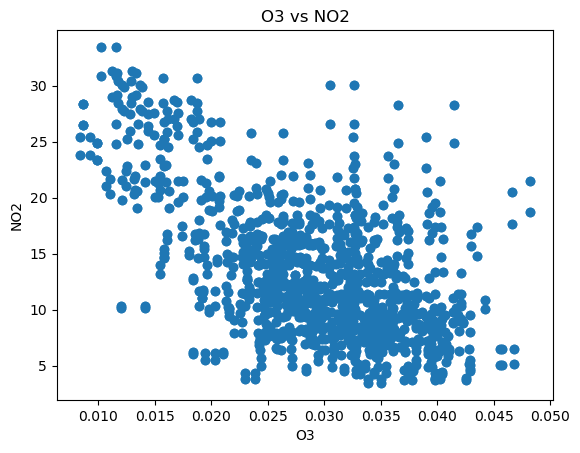

In [4]:
#Make scatter plot of all O3 and NO2 data
plt.scatter(df_all["Arithmetic Mean_x"], df_all["Arithmetic Mean_y"])

plt.xlabel("O3")
plt.ylabel("NO2")
plt.title("O3 vs NO2")
plt.show()

In [8]:
print(df_all.columns)

Index(['State Code_x', 'County Code_x', 'Site Number_x', 'Parameter Code_x',
       'POC_x', 'Latitude_x', 'Longitude_x', 'Datum_x', 'Parameter Name_x',
       'Duration Description_x', 'Pollutant Standard_x', 'Date (Local)',
       'Year_x', 'Day In Year (Local)_x', 'Units of Measure_x',
       'Exceptional Data Type_x', 'Nonreg Observation Count_x',
       'Observation Count_x', 'Observation Percent_x',
       'Nonreg Arithmetic Mean_x', 'Arithmetic Mean_x',
       'Nonreg First Maximum Value_x', 'First Maximum Value_x',
       'First Maximum Hour_x', 'AQI_x', 'Daily Criteria Indicator_x',
       'Tribe Name_x', 'State Name_x', 'County Name_x', 'City Name_x',
       'Local Site Name_x', 'Address_x', 'MSA or CBSA Name_x', 'Data Source_x',
       'State Code_y', 'County Code_y', 'Site Number_y', 'Parameter Code_y',
       'POC_y', 'Latitude_y', 'Longitude_y', 'Datum_y', 'Parameter Name_y',
       'Duration Description_y', 'Pollutant Standard_y', 'Year_y',
       'Day In Year (Local)_y'

In [11]:
#determine what type each input is
print('Type of df: ', type(df_all))
print('Type of x: ', type('Arithmetic Mean_x'))
print('Type of df: ', type(df_all['Arithmetic Mean_x']))

Type of df:  <class 'pandas.core.frame.DataFrame'>
Type of x:  <class 'str'>
Type of df:  <class 'pandas.core.series.Series'>


In [55]:
#make data sets into arrays
xVal = np.array(df_all['Arithmetic Mean_x']).reshape((-1, 1))
yVal = np.array(df_all['Arithmetic Mean_y'])

reg = linear_model.LinearRegression()
reg.fit(xVal,yVal)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [56]:
print("Coefficients: \n", reg.coef_)
print("Intercept: \n", reg.intercept_)

Coefficients: 
 [-455.04638924]
Intercept: 
 26.56067749750978


In [57]:
#select out 80% of data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(xVal, yVal, test_size=0.20)

In [58]:
reg2 = linear_model.LinearRegression()
reg2.fit(X_train,y_train)
print("Coefficients: \n", reg2.coef_)
print("Intercept: \n", reg2.intercept_)

Coefficients: 
 [-461.63376671]
Intercept: 
 26.74236277279093


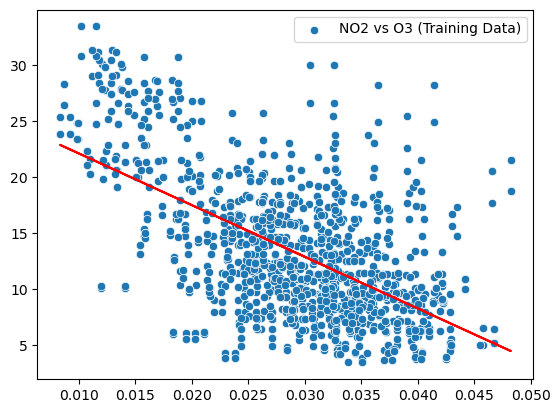

In [59]:
#make prediction from 80% data
yPred = reg2.predict(X_train)

#create scatter plot with training data
sns.scatterplot(x=X_train.flatten(), y=y_train, label='NO2 vs O3 (Training Data)')
plt.plot(X_train,yPred, color='r')

In [60]:
#mean squared error from training data
from sklearn.metrics import mean_squared_error
mean_squared_error(y_train,yPred)

25.661392008951278

In [61]:
#plot test data
df_test = pd.DataFrame({'x' : X_test.ravel(), 'y' : y_test.ravel()})
df_test['yPred'] = reg2.predict(X_test)

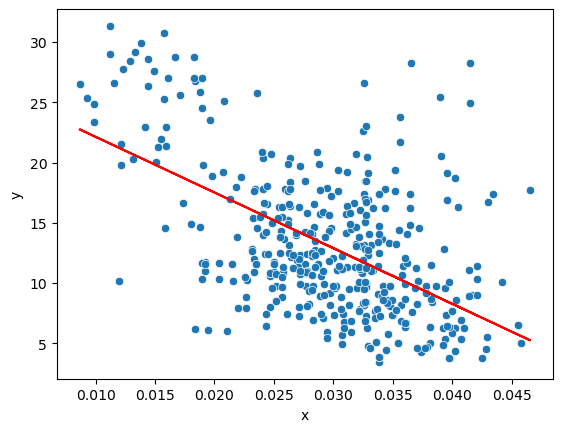

In [62]:
sns.scatterplot(data=df_test, x="x", y="y")
plt.plot(df_test['x'], df_test['yPred'], color='r')

In [64]:
mean_squared_error(df_test['y'],df_test['yPred'])
#df_all[['Arithmetic Mean_y', 'Units of Measure_y']].head(10)

25.505042607685706

In [65]:
#3. The mean squared error on the test data is 25.51 ppb.  A linear model performs fine for a general 
#estimate since there does seem to be a linear correlation between O3 and NO2, and a +/- 5ppb 
#NO2 difference probably wont make a huge difference considering air quality.

In [66]:
ds_ml.head()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.70,314.43,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.71,-1,-9.99,-0.99
3,1958,6,1958.4548,317.24,315.14,-1,-9.99,-0.99
4,1958,7,1958.5370,315.86,315.18,-1,-9.99,-0.99


In [70]:
#create data set with Mauna Loa data from before the year 2000
ML_before_2000=ds_ml[ds_ml['year'] < 2000]
ML_after_2000= ds_ml[ds_ml['year'] > 2000]
#check format of data 
print('Type of df: ', type(ML_before_2000))
print('Type of x: ', type('decimal date'))
print('Type of df: ', type(ML_before_2000['decimal date']))

Type of df:  <class 'pandas.core.frame.DataFrame'>
Type of x:  <class 'str'>
Type of df:  <class 'pandas.core.series.Series'>


In [71]:
#convert both data sets to array format
x_before_2000 = np.array(ML_before_2000['decimal date']).reshape((-1, 1))
y_before_2000 = np.array(ML_before_2000['average'])
x_after_2000 = np.array(ML_after_2000['decimal date']).reshape((-1, 1))
y_after_2000 = np.array(ML_after_2000['average'])

In [72]:
#create linear regression from data before year 2000
reg_b4_2000 = linear_model.LinearRegression()
reg_b4_2000.fit(x_before_2000,y_before_2000)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Text(0.5, 1.0, 'CO2 (ppm) vs Time')

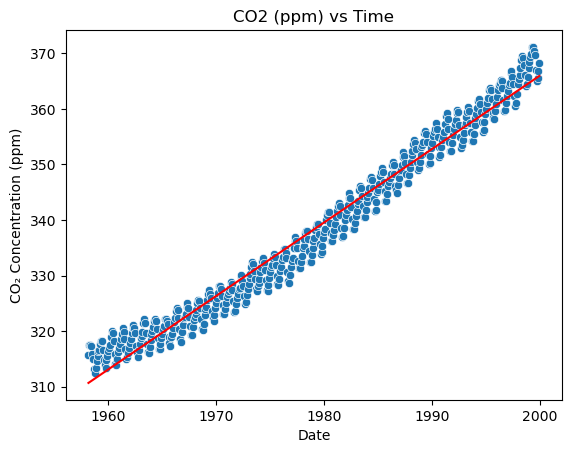

In [73]:
#predict with before 2000 data
y_b4_2000_pred= reg_b4_2000.predict(x_before_2000)
#create df for plotting
df_ML_b4_2000= pd.DataFrame({'x' : x_before_2000.ravel(), 'y' : y_before_2000.ravel()})
df_ML_b4_2000['yPred']= y_b4_2000_pred
# plot prediction
sns.scatterplot(data=df_ML_b4_2000, x="x", y="y")
plt.plot(df_ML_b4_2000['x'], df_ML_b4_2000['yPred'], color='r')
plt.xlabel("Date")
plt.ylabel("CO₂ Concentration (ppm)")
plt.title("CO2 (ppm) vs Time")


In [74]:
#plot after 2000 data
df_ML_after_2000 = pd.DataFrame({'decimal date' : x_after_2000.ravel(), 'average' : y_after_2000.ravel()})
df_ML_after_2000['yPred'] = reg_b4_2000.predict(x_after_2000)
df_ML_after_2000

,decimal date,average,yPred
0,2001.0417,370.76,367.365856
1,2001.1250,371.69,367.476086
2,2001.2083,372.63,367.586316
3,2001.2917,373.55,367.696678
4,2001.3750,374.03,367.806908
...,...,...,...
272,2023.7083,418.51,397.360323
273,2023.7917,418.82,397.470686
274,2023.8750,420.46,397.580916
275,2023.9583,421.86,397.691146


Text(0.5, 1.0, 'CO2 (ppm) vs Time')

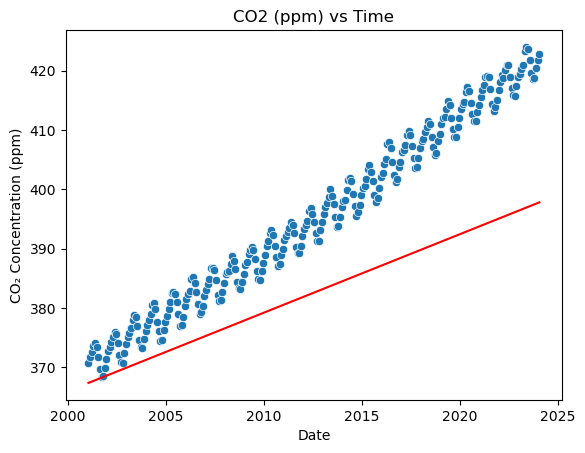

In [77]:
# plot the after 2000 data with the fit from the before 2000 model
sns.scatterplot(data=df_ML_after_2000, x="decimal date", y="average")
plt.plot(df_ML_after_2000['decimal date'], df_ML_after_2000['yPred'], color='r')
plt.xlabel("Date")
plt.ylabel("CO₂ Concentration (ppm)")
plt.title("CO2 (ppm) vs Time")

In [78]:
#calculate mean squared value
mean_squared_error(df_ML_after_2000['average'],df_ML_after_2000['yPred'])


208.3682639722378

In [79]:
#  The linear fit is about 14 ppm units off from the post-2000 real data and does not cross any of the data points except for a few at the beginning.  
# It doesn't capture the seasonal oscillations and did not predict how much higher CO2 concentrations were going to be after 2000.  Linear
# model only has time data and does not include other variables like CO2 emissions.